In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

RESULTS_FOLDER = Path("../../results/CNN_group_results")
RESULTS_FOLDER.mkdir(parents=True, exist_ok=True)

ACTIVITIES = ["walking", "walking_upstairs", "walking_downstairs"]

# Load the windows made by preprocessing_group as the CNN uses the windows, not the features.
data = np.load("../../data/processed/group/group_windows.npz")
windows = data["windows"] # (windows, 128 readings, 9 signals)
labels = pd.DataFrame({column: data[column] for column in ["split", "activity", "participant", "position"]})

# Swaps the labels for numbers as Keras cannot interpret the labels (walking = 0, walking_upstairs = 1, etc)
activity_to_number = {name: number for number, name in enumerate(ACTIVITIES)}
y_all = labels["activity"].map(activity_to_number).to_numpy()

print(f"Windows: {windows.shape}")
print(labels.groupby(["participant", "activity"]).size().unstack(fill_value=0))

Windows: (25232, 128, 9)
activity     walking  walking_downstairs  walking_upstairs
participant                                               
P01             9792                 713               847
P02             6399                 619               741
P03             4614                 620               887


In [6]:
def build_cnn():
    """Build a fresh, untrained CNN (called once per run, so every split starts from scratch)."""
    model = models.Sequential()
    model.add(layers.Input(shape=(128, 9))) # 128 readings and 9 diff signals
    model.add(layers.Conv1D(32, 3, activation="relu", padding="same"))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv1D(32, 3, activation="relu", padding="same"))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling1D(2))
    model.add(layers.Dropout(0.2))
    model.add(layers.Conv1D(64, 3, activation="relu", padding="same"))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv1D(64, 3, activation="relu", padding="same"))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling1D(2))
    model.add(layers.Dropout(0.3))
    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation="relu"))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(3))

    model.compile(optimizer="adam",
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=["accuracy"])
    return model

In [7]:
def run_cnn(is_test, name, file_name):
    # Prep the data, train on the CNN, then test it, print the results and return the macro F1 and training history.
    tf.keras.utils.set_random_seed(42)

    X_train, X_test = windows[~is_test], windows[is_test]
    y_train, y_test = y_all[~is_test], y_all[is_test]

    # Shuffle the training windows, so the 20% validation set contains every person and activity.
    shuffle = np.random.default_rng(42).permutation(len(X_train))
    X_train, y_train = X_train[shuffle], y_train[shuffle]

    # Scale each of the 9 signals to mean 0, standard deviation 1, learned from the training data only.
    mean = X_train.mean(axis=(0, 1))
    std = X_train.std(axis=(0, 1))
    X_train = (X_train - mean) / std
    X_test = (X_test - mean) / std

    # Class imbalance solution (stair windows count more to counter the walking-heavy data)
    counts = np.bincount(y_train, minlength=3)
    class_weight = {number: len(y_train) / (3 * count) for number, count in enumerate(counts)}

    # Train a fresh CNN
    model = build_cnn()
    history = model.fit(X_train, y_train, epochs=15, batch_size=64,
                        validation_split=0.2, class_weight=class_weight, verbose=0)

    # Predict and turn the numbers back into their respective labels.
    predictions = np.array(ACTIVITIES)[model.predict(X_test, verbose=0).argmax(axis=1)]
    y_test_names = np.array(ACTIVITIES)[y_test]

    # Results
    macro_f1 = f1_score(y_test_names, predictions, average="macro")
    print(f"===== CNN: {name} =====")
    print(f"Train: {len(y_train):,} windows   Test: {len(y_test):,} windows")
    print(f"Accuracy: {accuracy_score(y_test_names, predictions):.3f}")
    print(f"Macro F1: {macro_f1:.3f}\n")
    print(classification_report(y_test_names, predictions, labels=ACTIVITIES, digits=3, zero_division=0))

    # Confusion matrix
    ConfusionMatrixDisplay.from_predictions(y_test_names, predictions, labels=ACTIVITIES, normalize="true",
                                            cmap="Blues", xticks_rotation=30)
    plt.title(f"CNN: {name}")
    plt.tight_layout()
    plt.savefig(RESULTS_FOLDER / f"CNN_group_{file_name}_confusion_matrix.png", dpi=150)
    plt.show()

    # Scores per activity
    report = pd.DataFrame(classification_report(y_test_names, predictions, labels=ACTIVITIES,
                                                output_dict=True, zero_division=0)).T
    per_activity = report.loc[ACTIVITIES, ["precision", "recall", "f1-score"]]
    per_activity.plot(kind="bar", figsize=(7, 4), ylim=(0, 1), rot=0)
    plt.title(f"CNN: scores per activity ({name})")
    plt.ylabel("Score")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(RESULTS_FOLDER / f"CNN_group_{file_name}_per_activity.png", dpi=150)
    plt.show()

    return macro_f1, history

===== CNN: 70/30 by recording =====
Train: 17,131 windows   Test: 8,101 windows
Accuracy: 0.971
Macro F1: 0.922

                    precision    recall  f1-score   support

           walking      0.999     0.974     0.986      6935
  walking_upstairs      0.878     0.930     0.903       626
walking_downstairs      0.789     0.983     0.876       540

          accuracy                          0.971      8101
         macro avg      0.889     0.962     0.922      8101
      weighted avg      0.975     0.971     0.972      8101



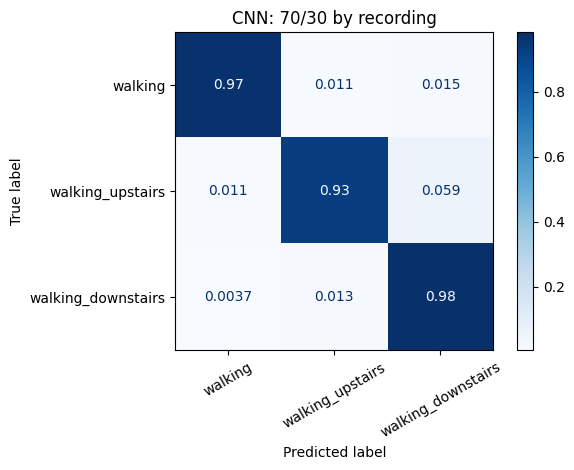

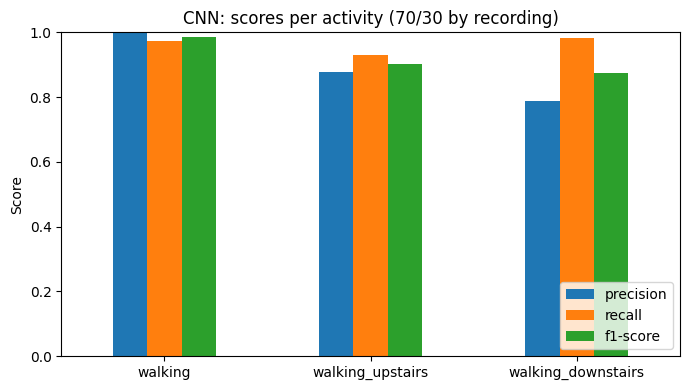

In [8]:
# 70/30 split by recording (read from the split column)
results = {}

is_test = (labels["split"] == "test").to_numpy()
results["70/30 by recording"], history_70_30 = run_cnn(is_test, "70/30 by recording", "70_30")

===== CNN: train on others, test on P01 (pocket) =====
Train: 13,880 windows   Test: 11,352 windows
Accuracy: 0.291
Macro F1: 0.200

                    precision    recall  f1-score   support

           walking      0.980     0.262     0.413      9792
  walking_upstairs      0.091     0.864     0.165       847
walking_downstairs      0.023     0.022     0.023       713

          accuracy                          0.291     11352
         macro avg      0.365     0.383     0.200     11352
      weighted avg      0.854     0.291     0.370     11352



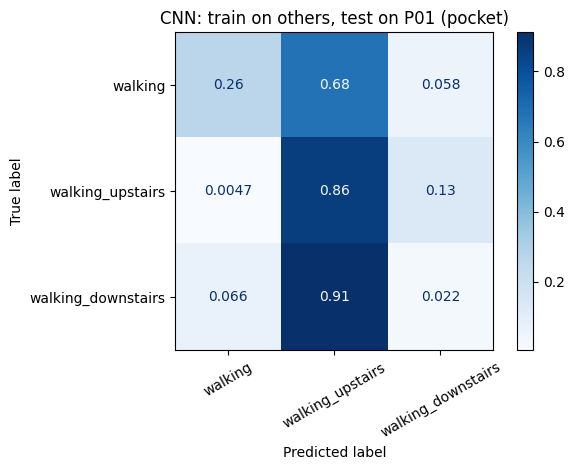

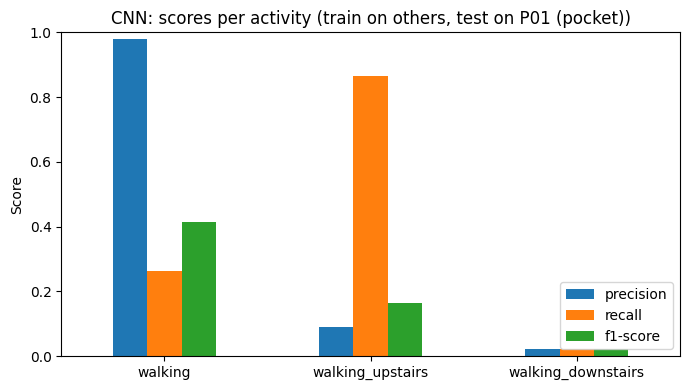

===== CNN: train on others, test on P02 (waist) =====
Train: 17,473 windows   Test: 7,759 windows
Accuracy: 0.549
Macro F1: 0.311

                    precision    recall  f1-score   support

           walking      0.834     0.620     0.711      6399
  walking_upstairs      0.102     0.354     0.158       741
walking_downstairs      0.078     0.053     0.063       619

          accuracy                          0.549      7759
         macro avg      0.338     0.342     0.311      7759
      weighted avg      0.703     0.549     0.606      7759



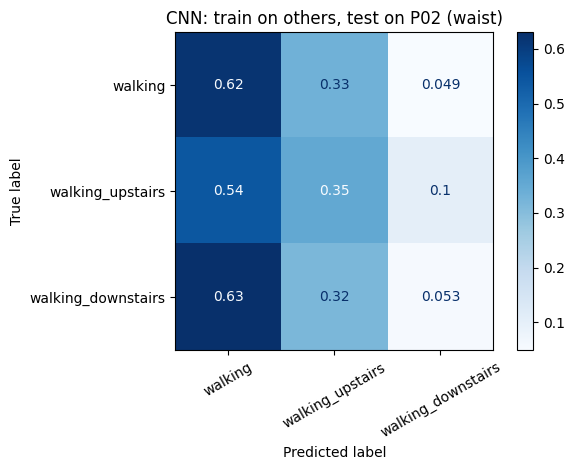

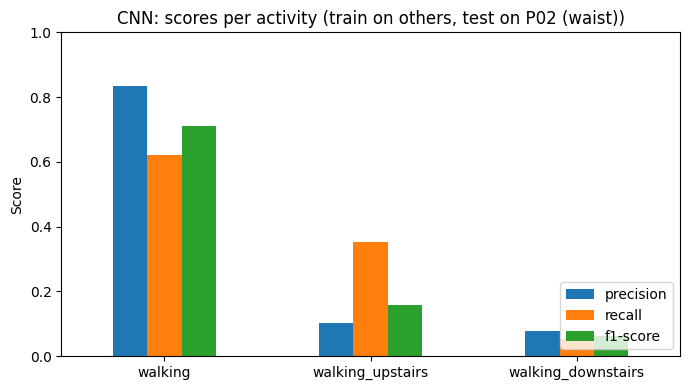

===== CNN: train on others, test on P03 (hand) =====
Train: 19,111 windows   Test: 6,121 windows
Accuracy: 0.419
Macro F1: 0.284

                    precision    recall  f1-score   support

           walking      0.801     0.503     0.618      4614
  walking_upstairs      0.355     0.092     0.147       887
walking_downstairs      0.053     0.258     0.089       620

          accuracy                          0.419      6121
         macro avg      0.403     0.285     0.284      6121
      weighted avg      0.661     0.419     0.496      6121



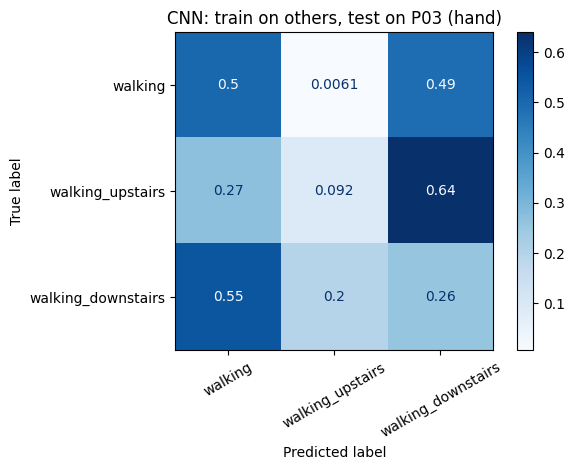

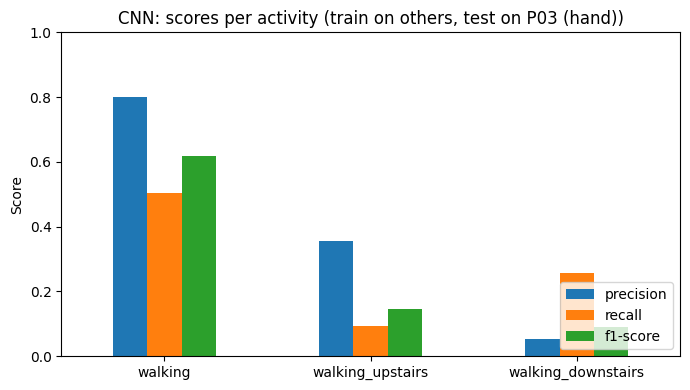

In [9]:
# Train on two people, test on the third (3 runs, alternating test person)
for person in sorted(labels["participant"].unique()):
    is_test = (labels["participant"] == person).to_numpy()
    position = labels.loc[is_test, "position"].iloc[0]
    name = f"train on others, test on {person} ({position})"
    results[f"Test on {person} ({position})"], _ = run_cnn(is_test, name, f"test_{person}")

In [10]:
# Summary of the 4 runs results
held_out_scores = [score for split, score in results.items() if split.startswith("Test on")]
results["Leave-one-participant-out average"] = sum(held_out_scores) / len(held_out_scores)

summary = pd.Series(results, name="Macro F1").round(3).to_frame()
summary.to_csv(RESULTS_FOLDER / "CNN_group_summary.csv")
summary

,Macro F1
70/30 by recording,0.922
Test on P01 (pocket),0.200
Test on P02 (waist),0.311
Test on P03 (hand),0.284
Leave-one-participant-out average,0.265


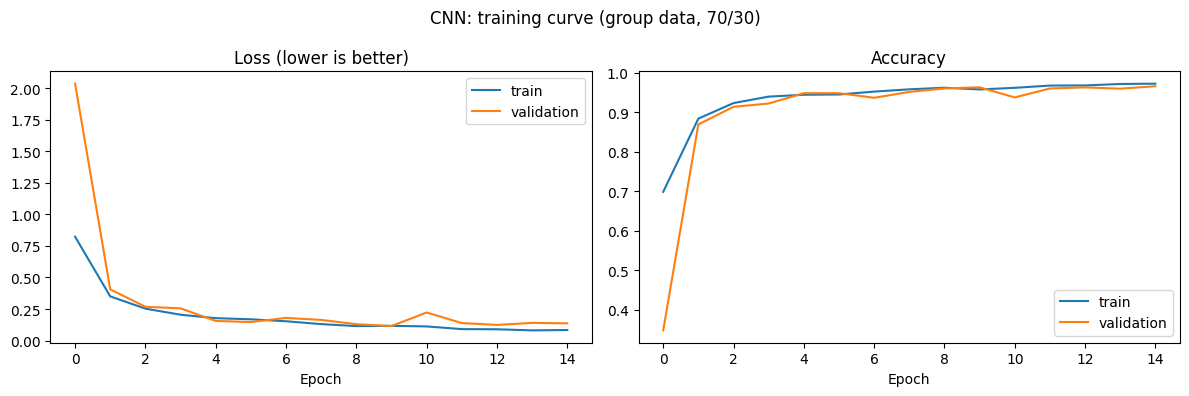

In [11]:
# Training curve graph (from the 70/30 run)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history_70_30.history["loss"], label="train")
ax1.plot(history_70_30.history["val_loss"], label="validation")
ax1.set_title("Loss (lower is better)")
ax2.plot(history_70_30.history["accuracy"], label="train")
ax2.plot(history_70_30.history["val_accuracy"], label="validation")
ax2.set_title("Accuracy")
for ax in (ax1, ax2):
    ax.set_xlabel("Epoch")
    ax.legend()
plt.suptitle("CNN: training curve (group data, 70/30)")
plt.tight_layout()
plt.savefig(RESULTS_FOLDER / "CNN_group_training_curve.png", dpi=150)
plt.show()